# TL;DR:

KMeans: fit, predict, inertia, centroids

```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
model.fit(samples)
labels = model.predict(samples)
model.fit_predict(samples) # why not both on same sample?
centroids = model.cluster_centers_ # x and y coordinates of centroids
inertia = model.inertia_ # lower = better
```
---

crosstab: "confusion matrix"
```python
import pandas as pd 
pd.crosstab(index = df['labels'], columns = df['varieties'])
```
---

Pipelines: standardscaler + kmeans
```python
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
kmeans = KMeans()
pipeline = make_pipeline(scaler, kmeans)
pipeline.fit(samples)
```
---

Normalizer: tricky
- normalization per row, and not column
- normalization per sample, and not feature

```python
from sklearn.preprocessing import Normalizer
import pandas as pd 
df = pd.read_csv('tables/company-stock-movements-2010-2015-incl.csv').filter(regex = '\d-')

norm = Normalizer()

(
    pd.DataFrame(
        norm.fit_transform(df))
    .applymap(lambda x: x**2)
    .sum(axis = 1)
    ) # all results are 1
 ```


unit norm (from normalizer)  
In machine learning, a unit norm is a vector that has a length or magnitude of 1. It is used to normalize the data so that the magnitude of the features does not affect the performance of the model. The most common unit norm is the L2 norm, which is also known as the Euclidean norm. It is defined as the square root of the sum of the squared values of each element in the vector. Other norms include L1 norm and max norm1.

---

Dendrogram, linkage

```python
from scipy.cluster.hierarchy import linkage, dendrogram 

#calculate the linkage: with single, it's bad
mergings = linkage(df.drop('label', axis = 1), method = 'single')

# plot dendrogram
dendrogram(
    mergings, 
    labels = df['label'].values,
    leaf_rotation=90,
    leaf_font_size=6
)
plt.show()
```
---


Ex: hierarchical clustering + dendrogram + standardization + flat cluster + crosstab

```python
from scipy.cluster.hierarchy import fcluster, linkage, dendrogram 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
standardized_samples = scaler.fit_transform(samples)

mergings = linkage(standardized_samples, method = 'complete') # longest distance between clusters
labels = fcluster(mergings, t= 6,  criterion = 'distance')
samples_full['labels'] = labels 
ct = pd.crosstab(samples_full['labels'], samples_full['varieties'])

display(ct)
dendrogram(mergings)
plt.show()
```
---

T-SNE (convert Xd tables to 2d tables)
```python
from sklearn.manifold import TSNE

model = TSNE(learning_rate = 50)
tsne_features = model.fit_transform(normalized_movements) #returns a 2d table

xs = tsne_features[:,0]
ys = tsne_features[:,1]

plt.scatter(xs, ys)
```
---
---

PCA
```python
from sklearn.decomposition import PCA
model = PCA()
pca_features = model.fit_transform(grains)

plt.scatter(pca_features[:,0], pca_features[:,1])
plt.axis('equal')

correlation, pvalue = pearsonr(pca_features[:,0], pca_features[:,1])
correlation

expl_var = model.explained_variance_
plt.bar(range(len(samples.columns)), expl_var)

plt.scatter(grains[0], grains[1])

# get the mean of the grain samples: mean
mean = model.mean_

# Get the first principal component:first_pc
first_pc = model.components_[0,:]

# Plot first_pc as an arrow, starting at mean
plt.arrow(mean[0], mean[1], first_pc[0], first_pc[1], color = 'red')


NMF: can be by a online newspaper that recommends similar articles
NMF to word frequency arrays
uses tf-idf for word frequency

# 1: Unsupervised learning

Unsupervised learning finds patterns in data ...  
but __without__ a specific prediction task in mind!



Datase: Iris  
- 3 species: Setosa, Versicolor, Virginica   
  
- 4 features: 
    - for each [Petal,Sepal]:
        - length,  width  



Iris data is 4-dimensional
- Columns are measurements (the __features__)
- Rows represent iris plants (the __samples__)

K-means clustering
- Finds clusters of samples
- Number of flusters must be specified

https://www.youtube.com/watch?v=4b5d3muPQmA
- clustering algorithm: aims to partition n observations into k clusters

```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
model.fit(samples)

labels = model.predict(samples)
print(labels)

new_labels = model.predict(new_samples)
print(new_labels)

import matplotlib.pyplot as plt
xs = samples[:,0]
ys = samples[:,2]
plt.scatter(xs, ys, c = labels)
plt.show()
```

cluster labels for new samples
- new samples can be assigned to existing clusters
- k-means remembers the mean of each cluster (the "centroids")
- finds the nearest centroid to each  new sample 

Time to practice!

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Text(0.5, 1.0, 'KMeans: 3 clusters. Centroids: black "diamonds"')

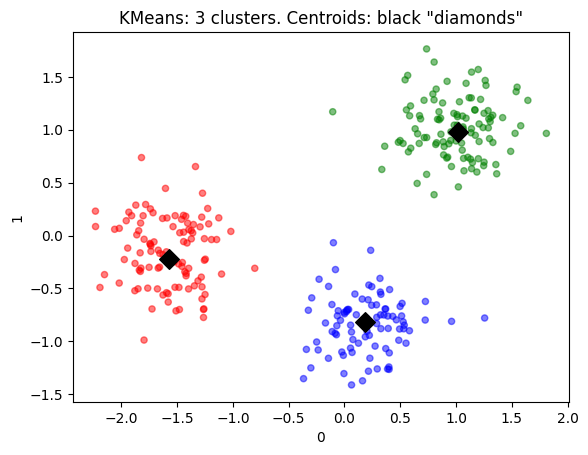

In [89]:
# import KMeans
from sklearn.cluster import KMeans 
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 

# Import dataset 
points = pd.read_csv('tables/points.csv')
new_points = pd.read_csv('tables/new_points.csv')

# Create a KMEans instance with 3 clusters: model
model = KMeans(n_clusters = 3)

# fit model to points
model.fit(points)

# Determine the cluser labels of new_points: labels
labels = model.predict(new_points)
dic = {0:'r', 1:'g', 2:'b'}

labels2 = [dic[k] for k in labels]
ax = new_points.plot.scatter(0,1, c = labels2, alpha = 0.5)

# Assign the cluster centers: centroids
centroids = model.cluster_centers_ 
pd.DataFrame(centroids).plot.scatter(0,1, ax = ax, marker = 'D', s = 100 , c = 'k')

plt.title('KMeans: 3 clusters. Centroids: black "diamonds"')

Evaluating a cluster: intertia

- Check correspondence. Ex: Iris species - compare 3 species with KNN 3 clusters

```python
import pandas as pd 
df = pd.DataFrame({'labels': labels, 'species': species})
ct = pd.crosstab(df['labels'], df['species'])
```


Intertia measures clustering quality
- lower is better

```python
from sklearn import KMeans

model = KMeans(n_clusters = 3)
model.fit(samples)
print(model.inertia_)
```
- More clusters -> lower inertia

How many clusters to choose? Inertia vs n_clusters
- choose the "elbow"

Let's pratice!

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will c

KeyboardInterrupt: 

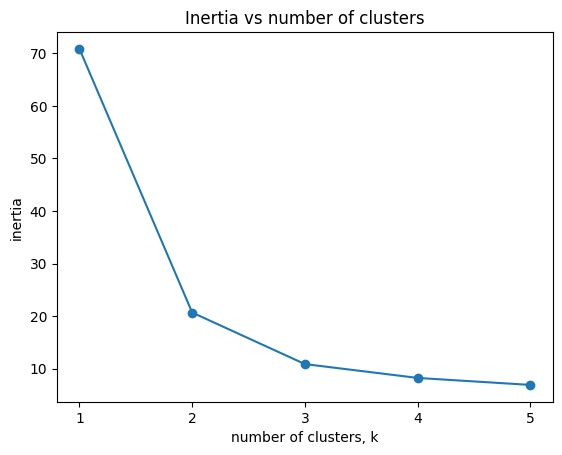

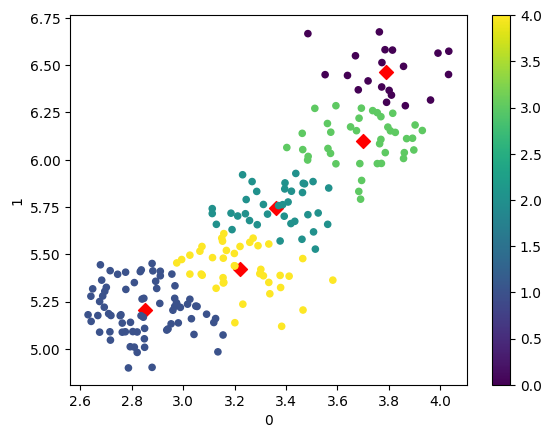

In [90]:
import pandas as pd 
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

ks = range(1,6)
inertias = []

samples = pd.read_csv('tables/seeds-width-vs-length.csv', header = None).set_axis(['width','length'], axis = 1)

for k in ks:
    # Create a KMeans instance with k clusters:
    model = KMeans(n_clusters = k)

    # Fit model to samples
    model.fit(samples)

    # append the inertia to the list of inertias
    inertias.append(model.inertia_)

# plot ks vs inertias
plt.plot(ks, inertias, '-o')
plt.xlabel('number of clusters, k')
plt.ylabel('inertia')
plt.xticks(ks)
plt.title('Inertia vs number of clusters')


## by sergio
centroids = model.cluster_centers_
ax = pd.DataFrame(centroids).plot.scatter(0,1, s = 50, marker = 'D', c= 'red')

samples.plot.scatter(x = 'width', y = 'length', c = model.predict(samples), cmap = 'viridis', ax = ax)
plt.title('seed length vs width, the KMeans groups and centroids')

In [ ]:
pd.read_csv('tables/seeds-width-vs-length-varieties.csv')

,length,width,varieties
0,3.312,5.763,Kama wheat
1,3.333,5.554,Kama wheat
2,3.337,5.291,Kama wheat
3,3.379,5.324,Kama wheat
4,3.562,5.658,Kama wheat
...,...,...,...
205,2.981,5.137,Canadian wheat
206,2.795,5.140,Canadian wheat
207,3.232,5.236,Canadian wheat
208,2.836,5.175,Canadian wheat


In [ ]:
# Create a KMeans model with 3 clusters: model
model =KMeans(n_clusters = 3)

# Use fit_predict to fit model to obtain cluster labels: labels
samples = pd.read_csv('tables/seeds-width-vs-length-varieties.csv')
labels = model.fit_predict(samples[['width','length']])

# create a DataFrame with labels and varieties as columns: df
samples['labels'] = labels
samples

# create crosstab: ct
ct = pd.crosstab(samples['labels'], samples['varieties'])
ct

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


varieties,Canadian wheat,Kama wheat,Rosa wheat
labels,,,
0,0,1,56
1,69,18,0
2,1,51,14


Transforming features for better clustering

Dataset: Piedment wines
- 3 distinct varieties: Barolo, Grignolino and Barbera

Poor fitting: very different variances: data not concave?
```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
labels = model.fit_predict(samples)

StandardScaler

0 mean and variance 1

```python
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(samples)
StandardScaler(copy = True, with_mean = True, with_std = True)
samples_scaled = scaler.transform(samples) # note that it is not predict()

StandardScaler, then KMeans: pipeline
Better fitting
```python
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline

scaler = StandardScaler()
kmeans = KMeans(n_clusters = 3)
pipeline = make_pipeline(scaler, kmeans)
pipeline.fit(samples)

Obs: other preprocessing steps:
- StandardScaler
- MaxAbsScaler
- Normalizer

Time to Practice!


In [ ]:
# perform necessary imports 
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans 
import pandas as pd 

# import data
samples = pd.read_csv('tables/fish.csv')

# create scaler
scaler = StandardScaler()

# create Kmeans
kmeans = KMeans(n_clusters = 4)

# create pipeline
pipeline = make_pipeline(scaler, kmeans)


In [ ]:
# fit the pipeline to samples
pipeline.fit(samples.filter(regex = '\d')) #removing samples col

# calculate the cluster labels
labels = pipeline.predict(samples.filter(regex = '\d'))

# add labels to samples 
samples['labels'] = labels
# create crosstab
ct = pd.crosstab(samples['labels'], samples['species'])
ct

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


species,Bream,Pike,Roach,Smelt
labels,,,,
0,0,17,0,0
1,1,0,19,1
2,33,0,1,0
3,0,0,0,13


In [ ]:
#Extra exercise: stock price movements

# import libraries
import pandas as pd 
from sklearn.preprocessing import Normalizer 
from sklearn.cluster import KMeans 
from sklearn.pipeline import make_pipeline 

# create normalizer 
normalizer = Normalizer()

# create KMeans
kmeans = KMeans(n_clusters = 10)

# make pipeline chaining normalizer and kmeans
pipeline = make_pipeline(normalizer, kmeans)

# import data
movements = pd.read_csv('tables/company-stock-movements-2010-2015-incl.csv')
movements = movements.rename(columns = {'Unnamed: 0':'companies'})
# fit
pipeline.fit(movements.filter(regex = '\d-'))

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Pipeline(steps=[('normalizer', Normalizer()),
                ('kmeans', KMeans(n_clusters=10))])

In [ ]:
# predict
labels = pipeline.predict(movements.filter(regex = '\d-'))

movements['labels'] = labels 

movements[['labels','companies']].sort_values('labels')


,labels,companies
35,0,Navistar
15,0,Ford
42,1,Royal Dutch Shell
43,1,SAP
44,1,Schlumberger
19,1,GlaxoSmithKline
46,1,Sanofi-Aventis
39,1,Pfizer
12,1,Chevron
37,1,Novartis


<Axes: >

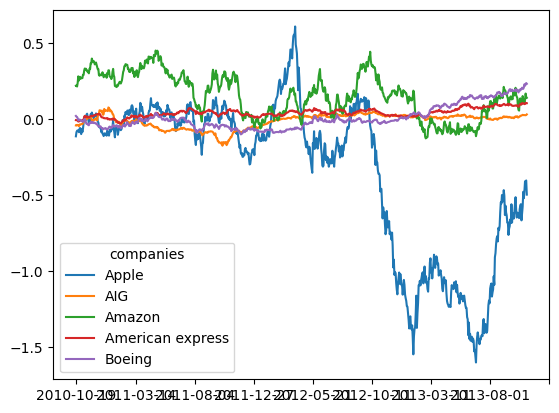

In [ ]:
(
    movements
    # .query('labels == 1')
    .set_index('companies')
    .filter(regex = '\d-')
    .T
    .rolling(window = 200)
    .mean()
    .T
    .head(5)
    .T
    .plot()
    )

In [ ]:
df = samples.filter(regex = '\d')
df

,0,1,2,3,4,5
0,242.0,23.2,25.4,30.0,38.4,13.4
1,290.0,24.0,26.3,31.2,40.0,13.8
2,340.0,23.9,26.5,31.1,39.8,15.1
3,363.0,26.3,29.0,33.5,38.0,13.3
4,430.0,26.5,29.0,34.0,36.6,15.1
...,...,...,...,...,...,...
80,950.0,48.3,51.7,55.1,16.2,11.2
81,1250.0,52.0,56.0,59.7,17.9,11.7
82,1600.0,56.0,60.0,64.0,15.0,9.6
83,1550.0,56.0,60.0,64.0,15.0,9.6


# 2: Visualizing hierarchies:
- "t-SNE": 2D map of dataset
- Hierarchical clustering

Hierarchical clustering: dendrogram
- read from bottom-up
- vertical lines: clusters
```python
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

mergins = linkage(samples, method = 'complete')

dendrogram(
    mergins,
    labels = country_names,
    leaf_rotation = 90,
    leaf_font_size = 6
)
plt.show()


Let's practice!

array([[33.        , 36.        ,  0.27162909,  2.        ],
       [21.        , 26.        ,  0.31365739,  2.        ],
       [18.        , 43.        ,  0.32846589,  3.        ],
       [38.        , 41.        ,  0.34657328,  2.        ],
       [19.        , 22.        ,  0.37233454,  2.        ]])

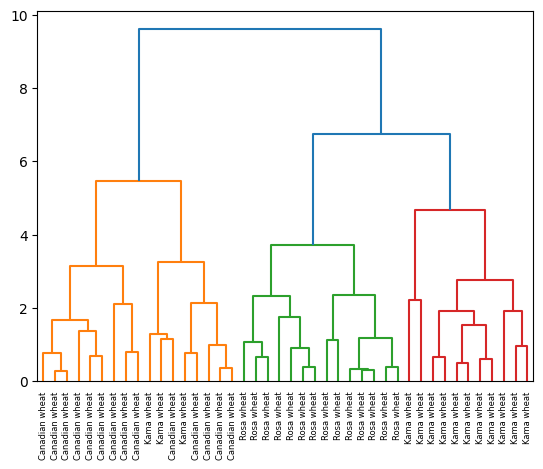

In [ ]:
import pandas as pd 
from scipy.cluster.hierarchy import linkage, dendrogram 
import matplotlib.pyplot as plt 

samples_full = pd.read_csv('tables/grains.csv')
samples = samples.filter(regex = '\d')
# calculate the linkage
mergings = linkage(samples, method = 'complete')
display(mergings[:5,:])

# Plot the dendrogram
# dendrograThe code is plotting a dendrogram using the hierarchical clustering method.
varieties = samples_full['varieties'].values
dendrogram(
    mergings,
    labels = varieties, 
    leaf_rotation = 90, 
    leaf_font_size = 6
)
plt.show()

'mergings:'

array([[42.        , 49.        ,  0.58499795,  2.        ],
       [12.        , 57.        ,  0.67355098,  2.        ],
       [ 5.        , 26.        ,  0.69371159,  2.        ],
       [21.        , 48.        ,  0.75062554,  2.        ],
       [52.        , 60.        ,  0.78536856,  3.        ]])

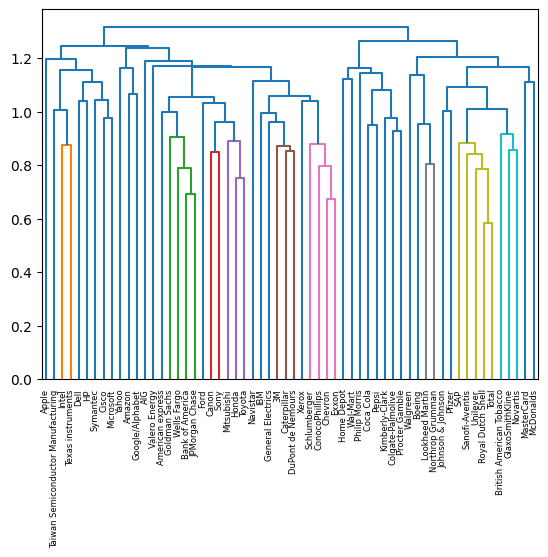

In [ ]:
import pandas as pd 
from sklearn.preprocessing import normalize 
from scipy.cluster.hierarchy  import dendrogram, linkage

# import bank data
movement_full = pd.read_csv('tables/company-stock-movements-2010-2015-incl.csv')
movement_full = movement_full.rename(columns = {'Unnamed: 0': 'companies'})
movement = movement_full.filter(regex = '\d-')

# normalize the movements
normalized_movements = normalize(movement)

# calculate linkage
mergings = linkage(normalized_movements, method = 'complete')

display('mergings:', mergings[:5,:])

# plot
dendrogram(
    mergings, 
    labels = movement_full['companies'].values,
    leaf_rotation = 90,
    leaf_font_size= 6

)
plt.show()


Cluster labels in hierarchical clustering  
Intermediate stage in clustering: height
Height = distance between merging clusters
height measured via linakge method

Linkage methods:
- ex: complete: distance between clusters is max dist between samples
- ex: linkage(samples, method = 'complete')




Extract height (linkage method): fcluster


```python
from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import fcluster
mergings = likage(samples, method = 'complete')
labels = fcluster(mergings, 15, criterion = 'distance')
pairs = pd.DataFrame({'labels':labels, 'countries':country_names})
```


let's practice!

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero


,From country,To country,Jury A,Jury B,Jury C,Jury D,Jury E,Jury Rank,Televote Rank,Jury Points,Televote Points
0,Albania,Belgium,20,16,24,22,24,25,14,\n,\n
1,Albania,Czech Republic,21,15,25,23,16,22,22,\n,\n
2,Albania,The Netherlands,22,14,23,24,21,24,24,\n,\n
3,Albania,Azerbaijan,19,12,11,21,11,13,19,\n,\n
4,Albania,Hungary,8,13,9,14,9,10,10,1,1


,Jury A,Jury B,Jury C,Jury D,Jury E,Jury Rank,Televote Rank
To country,,,,,,,
Armenia,12.146341,10.926829,12.975610,12.585366,11.926829,11.731707,10.243902
Australia,5.317073,6.000000,4.951220,5.390244,5.390244,3.902439,6.609756
Austria,15.878049,16.414634,17.463415,16.243902,16.829268,17.682927,8.780488
Azerbaijan,16.121951,15.268293,15.097561,16.658537,14.926829,16.121951,16.024390
Belgium,12.341463,11.097561,10.195122,10.780488,10.756098,10.756098,13.634146


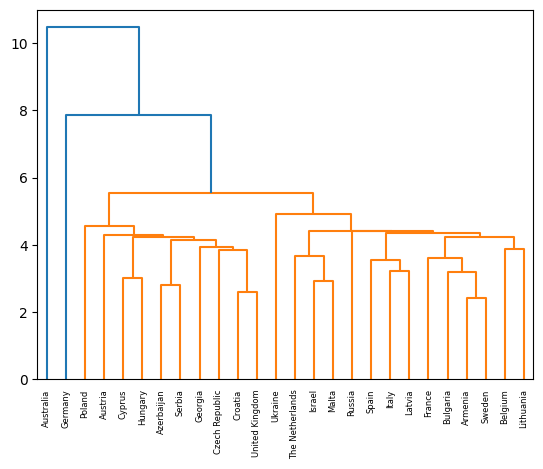

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram 


samples_full = pd.read_excel('tables/ESC-2016-grand_final-full_results.xls', header = 1)
samples = samples_full.set_index('To country').select_dtypes('number').groupby('To country').mean()
samples


display(samples_full.head(), samples.head())

#calculate the linkage: with single, it's bad
mergings = linkage(samples, method = 'single')

# plot dendrogram
dendrogram(
    mergings, 
    labels = samples.index.values,
    leaf_rotation=90,
    leaf_font_size=6
)
plt.show()

varieties,Canadian wheat,Kama wheat,Rosa wheat
labels,,,
1,0,14,70
2,0,56,0
3,70,0,0


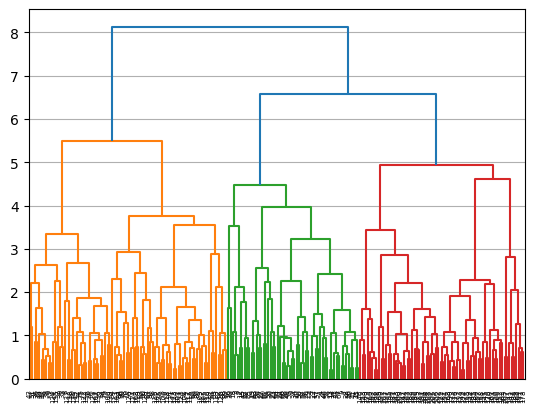

In [ ]:
import pandas as pd 
from scipy.cluster.hierarchy import fcluster, linkage, dendrogram 
from sklearn.preprocessing import Normalizer, StandardScaler
import matplotlib.pyplot as plt

samples_full = pd.read_csv('tables/seeds_full_varieties.csv')
samples = samples_full.drop('varieties', axis = 1)

# 
scaler = StandardScaler()
standardized_samples = scaler.fit_transform(samples)

# linkage: hierarchical clustering
mergings = linkage(standardized_samples, method = 'complete') # longest distance between clusters
# flat clusters: set a height & retrieve clusters at this level
labels = fcluster(mergings, t= 6,  criterion = 'distance')

samples_full['labels'] = labels 
ct = pd.crosstab(samples_full['labels'], samples_full['varieties'])

display(ct)

# plot the hierarchical clustering as a dendrogram
dendrogram(mergings)
plt.grid(axis = 'y')
plt.show()

t-SNE

t-distributed stochastic neighbor embedding
- maps lots of stuff in a 2D space (or 3D) on nearness of samples

t-SNE in sklearn
- only has fit_transform()
- try values between 50 and 200
- different results every time!
```python
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
model = TSNE(learning_rate = 100)
transformed = model.fit_transform(samples)
xs = transformed[:,0]
ys = transformed[:,1]
plt.scatter(xs, ys, c = species)
plt.show()

Time to practice!

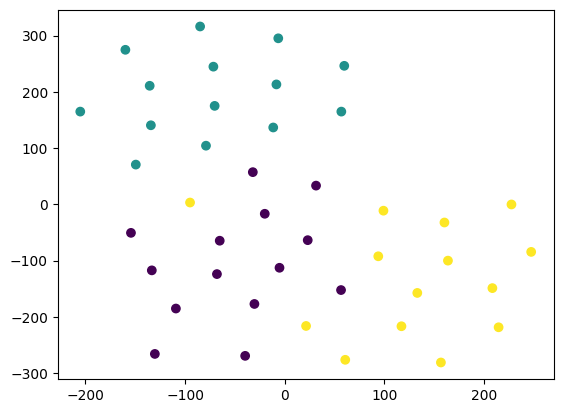

In [ ]:
import pandas as pd 
from sklearn.manifold import TSNE 
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt 

#%%
samples_full = pd.read_csv('tables/grains.csv')
samples = samples_full.drop('varieties', axis = 1)
scaler = StandardScaler()
std_samples = scaler.fit_transform(samples)

dic = {x:y for x,y in zip(samples_full['varieties'].unique(), range(0,3))}

# create TSNE instance
model = TSNE(learning_rate = 200)

# Apply fit_transform to samples
tsne_features = model.fit_transform(std_samples)
df = pd.DataFrame(tsne_features, columns =[0,1])
plt.scatter(df[0], df[1], c = samples_full['varieties'].map(dic))




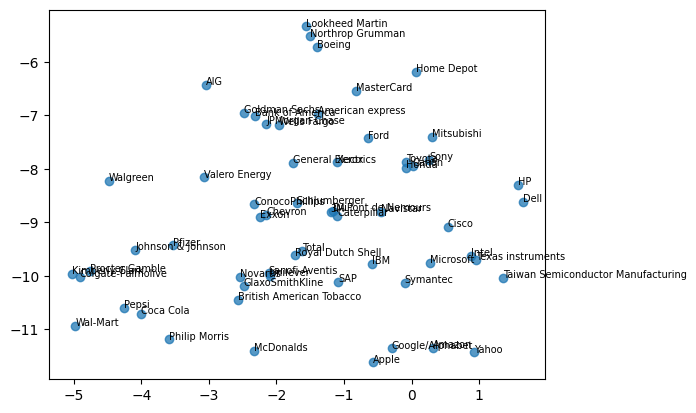

In [ ]:
import pandas as pd 
from sklearn.manifold import TSNE
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt 

movements_full = pd.read_csv('tables/company-stock-movements-2010-2015-incl.csv').rename(columns = {'Unnamed: 0':'companies'})
movements = movements_full.drop('companies', axis = 1)

norm = Normalizer()
model = TSNE(learning_rate = 50)

normalized_movements = norm.fit_transform(movements)
tsne_features = model.fit_transform(normalized_movements)

xs = tsne_features[:,0]
ys = tsne_features[:,1]

plt.scatter(xs, ys, alpha = 0.75)

for x, y, company in zip(xs, ys, movements_full['companies']):
    plt.annotate(company, (x,y), fontsize = 7)

In [ ]:
# 3: Princiapl Component Analysis

First step: "Decorrelation"
- aligns data with axes
- rotates data samples to be aligned with axes  
- Pricipal components = directions of variance   
- PCA aligns principal components with axes  
```python
from sklearn.decomposition import PCA
model = PCA()
model.fit(samples)
transformed = model.transform(samples)
print(model.components_)
```

results: same table shape
- columns = PCA features  
- values are de-correlated (pearson would be zero)  

Let's practice!

          0         1
0  1.000000  0.860415
1  0.860415  1.000000
0.8604149377143466 8.121332906194173e-63


(2.55985, 4.10315, -0.33375000000000093, 7.00875)

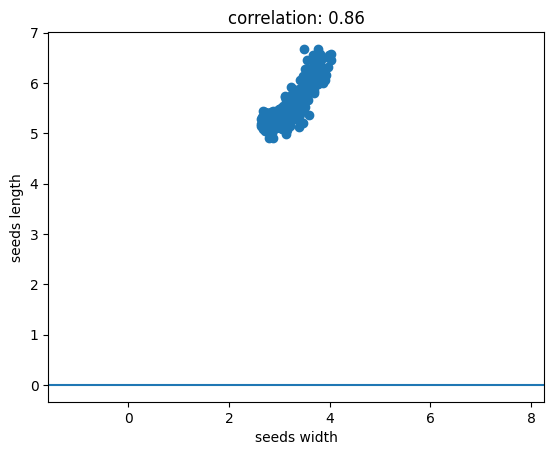

In [ ]:
import matplotlib.pyplot as plt 
import pandas as pd 
from scipy.stats import pearsonr

grains = pd.read_csv('tables/seeds-width-vs-length.csv', header = None)
grains

plt.scatter(grains[0], grains[1])
print(grains.corr())

correlation, pvalue = pearsonr(grains[0], grains[1])
print(correlation, pvalue)

plt.title(f'correlation: {round(correlation, 2)}')
plt.xlabel('seeds width')
plt.ylabel('seeds length')
plt.axhline(y = 0)
plt.axis('equal')


#

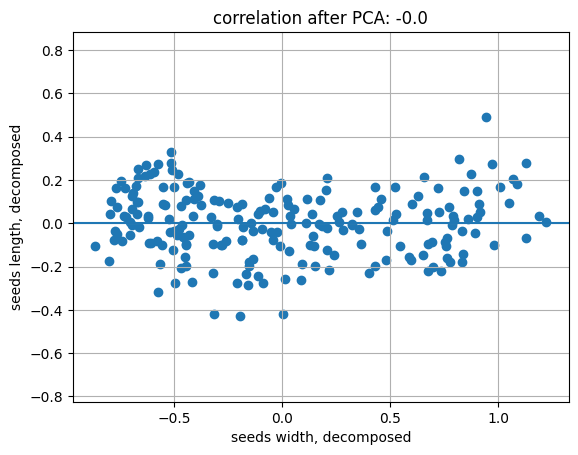

In [ ]:
from sklearn.decomposition import PCA

model = PCA()

pca_features = model.fit_transform(grains)

plt.scatter(pca_features[:,0], pca_features[:,1])
plt.axis('equal')

correlation, pvalue = pearsonr(pca_features[:,0], pca_features[:,1])
correlation

plt.title(f'correlation after PCA: {round(correlation, 2)}')
plt.xlabel('seeds width, decomposed')
plt.ylabel('seeds length, decomposed')
plt.axhline(y = 0)

plt.grid()

Intrinsinc dimension: PCA
- number of variables needed in a minimal representation of the data  
- number of features needed to apprximate the dataset 
- features = dimension = columns of dataset  
- if 3 features (x, y, z), but all data points lie on a plane (z the same for all): 2 intrinsinc dimensions 
- chart: y - variance; x = PCA feature (?)

Bing:
The difference between PCA variance and regular variance is that PCA variance is the proportion of the total variance explained by each principal component. It is calculated by dividing the eigenvalue of each principal component by the sum of all eigenvalues. Regular variance, on the other hand, is simply the average squared deviation from the mean.

```python
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(samples)
features = range(pca.n_components_)
plt.bar(features, pca.explained_variance_)
plt.xticks(features)
plt.ylabel('variance')
plt.xlabel('PCA feature')
plt.show()


Time to practice!

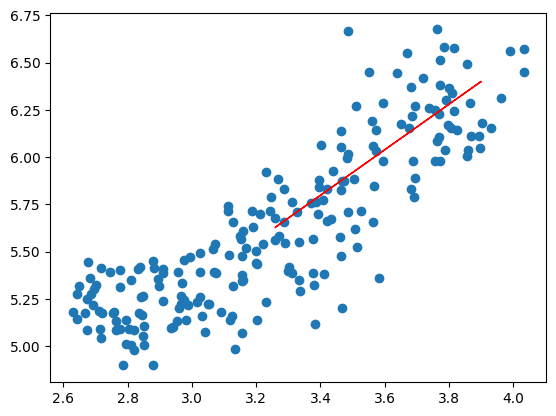

In [ ]:
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA 

# Make a scatter plot of the untransformed points
plt.scatter(grains[0], grains[1])

# Create a PCA instance: model
model = PCA() 


# Fit model to points
model.fit(grains)

# get the mean of the grain samples: mean
mean = model.mean_

# Get the first principal component:first_pc
first_pc = model.components_[0,:]

# Plot first_pc as an arrow, starting at mean

plt.arrow(mean[0], mean[1], first_pc[0], first_pc[1], color = 'red')

Text(0.5, 1.0, 'Scree plot: \nGraphical representation of the eigenvalues \nof factors of PCA High variance: Informative; low variance: noisy')

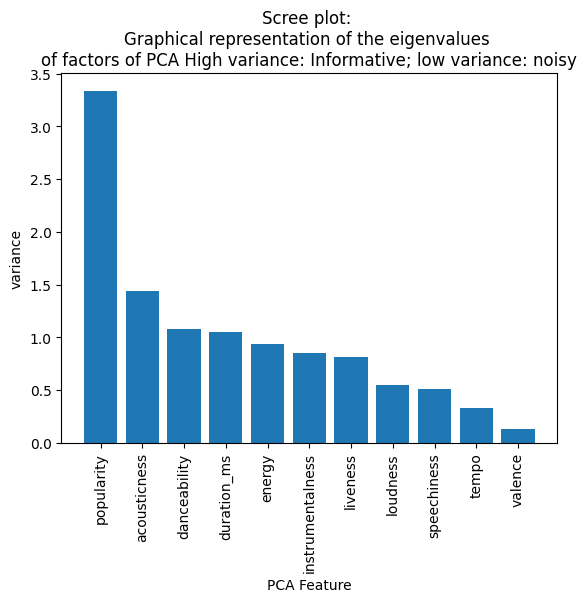

In [ ]:
from sklearn.pipeline import make_pipeline 
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

music_df = pd.read_csv('tables/music_clean.csv')
music_df = music_df.select_dtypes('number')

# Create a PCA instance: pca
pca = PCA()

# Create scaler
scaler = StandardScaler()

# create pipeline
pipeline = make_pipeline(scaler, pca)

# Fit the pipeline to dataset
pipeline.fit(music_df)

# Plot the explained variances
features = music_df.columns 

plt.bar(features, pca.explained_variance_)
plt.xticks(features, rotation = 90)
plt.xlabel("PCA Feature")
plt.ylabel('variance')
plt.title('''Scree plot: 
Graphical representation of the eigenvalues 
of factors of PCA High variance: Informative; low variance: noisy''')

Dimension reduction
- represents same data, using less features
- can be performed using PCA  
- keeps high variance (eigenvalue variance)

```python
from sklearn.decomposition import PCA
pca = PCA(n_comonents = 2)
pca.fit(samples)
transformed = pca.transform(samples)
print(transformed.samples)
```

Sparse arrays and csr_matrix
- scipy.sparce.csr_matrix instead of Numpy array
- csr_matrix remembers only the non-zero entries (save space!)
- csr_matrix = sklearn TruncatedSVD
```python
from sklearn.decomposition import TruncatedSVD
model = TruncatedSVD(n_components = 3)
model.fit(documents) # documents is csr_matrix
transformed = model.transform(documents)

Time to practice!

,1,2,3,4,5,6
0,242.0,23.2,25.4,30.0,38.4,13.4
1,290.0,24.0,26.3,31.2,40.0,13.8
2,340.0,23.9,26.5,31.1,39.8,15.1
3,363.0,26.3,29.0,33.5,38.0,13.3
4,430.0,26.5,29.0,34.0,36.6,15.1


array([[-0.50109735, -0.36878558, -0.34323399, -0.23781518,  1.0032125 ,
         0.25373964],
       [-0.37434344, -0.29750241, -0.26893461, -0.14634781,  1.15869615,
         0.44376493],
       [-0.24230812, -0.30641281, -0.25242364, -0.15397009,  1.13926069,
         1.0613471 ],
       [-0.18157187, -0.09256329, -0.04603648,  0.02896467,  0.96434159,
         0.20623332],
       [-0.00464454, -0.0747425 , -0.04603648,  0.06707608,  0.8282934 ,
         1.0613471 ]])

<BarContainer object of 6 artists>

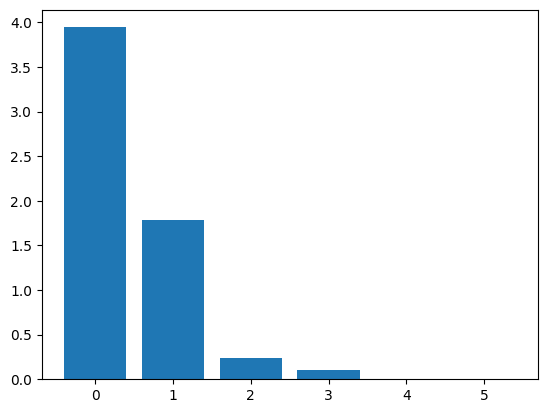

In [ ]:
import pandas as pd 
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

samples_full = pd.read_csv('tables/fish.csv', header = None)
samples = samples_full.drop(0, axis = 1)

# Scale the data (required to retrieve more useful dimensions)
scaler = StandardScaler()
scaled_samples = scaler.fit_transform(samples)
display(samples.head(), scaled_samples[:5,:])

# Create a PCA model with 2 components
pca = PCA()

# fit the PCA instances to the scaled samples
pca.fit(scaled_samples)

# Transform the scaled samples: pca_features
pca_features = pca.transform(scaled_samples)

# print the shape of features
pca_features.shape

expl_var = pca.explained_variance_
plt.bar(range(len(samples.columns)), expl_var)
plt.title('expl variance. Higher = better')

In [ ]:
# tripping... 

from sklearn.feature_extraction.text import TfidfVectorizer

documents = ['cats say meow', 'dogs say woof', 'dogs chase cats']

# Create a TfidfVectorizer
tfidf = TfidfVectorizer()

# fit transform
csr_mat = tfidf.fit_transform(documents)

# print results
print(csr_mat.toarray())

# get words
words = tfidf.get_feature_names_out()

words

[[0.51785612 0.         0.         0.68091856 0.51785612 0.        ]
 [0.         0.         0.51785612 0.         0.51785612 0.68091856]
 [0.51785612 0.68091856 0.51785612 0.         0.         0.        ]]


array(['cats', 'chase', 'dogs', 'meow', 'say', 'woof'], dtype=object)

In [ ]:
# clustering Wikipedia part I

# perform necessary imports 
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans 
from sklearn.pipeline import make_pipeline

# Create a TruncatedSVD instance: svd
svd = TruncatedSVD(n_components = 50)

# Create a KMeans instance: kmeans
kmeans = KMeans(n_clusters = 6)

# Create a pipeline: pipeline
pipeline = make_pipeline(svd, kmeans)

In [93]:
import wikipedia

titles = [
    # 'Sonic the Hedgehog 2',
    'Super Mario Bros 3',
    'Super Mario Bros 2',
    'Carl Sagann',
    'Neil Degrasse Tysonn',
    'Renato Aragao',
    'Dede Santana'
]

articles = {}
for k in titles:
    print(k)
    articles[k] = wikipedia.summary(k)
df = pd.DataFrame.from_dict(articles, orient = 'index', columns = ['articles'])
df.to_csv('tables/articles.csv')
pd.read_csv('tables/articles.csv')

Super Mario Bros 3
Super Mario Bros 2
Carl Sagann
Neil Degrasse Tysonn
Renato Aragao
Dede Santana


,Unnamed: 0,articles
0,Super Mario Bros 3,Super Mario Bros. 3 is a platform game develop...
1,Super Mario Bros 2,Super Mario Bros. 2 is a platform video game d...
2,Carl Sagann,"Carl Edward Sagan (; SAY-gən; November 9, 1934..."
3,Neil Degrasse Tysonn,Neil deGrasse Tyson (US: or UK: ; born Octobe...
4,Renato Aragao,"Antônio Renato Aragão (born January 13, 1935),..."
5,Dede Santana,"Manfried Sant'Anna (São Gonçalo, April 29, 193..."


In [94]:
from sklearn.decomposition import PCA , TruncatedSVD
from sklearn.cluster import KMeans 
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf= TfidfVectorizer()
articles = tfidf.fit_transform(df['articles'].values)

svd = TruncatedSVD(n_components = 50)
kmeans = KMeans(n_clusters = 3)
pipeline = make_pipeline(svd, kmeans)


pipeline.fit(articles)

labels = pipeline.predict(articles)

df['labels'] = labels
df

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


,articles,labels
Super Mario Bros 3,Super Mario Bros. 3 is a platform game develop...,0
Super Mario Bros 2,Super Mario Bros. 2 is a platform video game d...,0
Carl Sagann,"Carl Edward Sagan (; SAY-gən; November 9, 1934...",2
Neil Degrasse Tysonn,Neil deGrasse Tyson (US: or UK: ; born Octobe...,2
Renato Aragao,"Antônio Renato Aragão (born January 13, 1935),...",1
Dede Santana,"Manfried Sant'Anna (São Gonçalo, April 29, 193...",1


# 4. Non negative Matrix factorization (NMF)

NMF = non-negative matrix factorization  
dimenstion reduction tecnique  
Interpretable (unlike PCA)  
only non-negative values  
Can be used for   
- text analysis (with tf-idf) (tf = token frequency; idf reduces freq. word importance)
- image analysis

NMF has components, as PCA
nmf_features[i,:] * model.components_ == samples[i,:]


NMF in python:
```python
from sklearn.decomposition import NMF
model = NMF(n_components = 2)
model.fit(samples) # word-frequency array
nmf_features = model.transform(samples)
print(model.components_)

# reconstruction of a sample
print(samples[i,:])
print(nmf_features[i,:])



Let's practice!

In [1]:
from sklearn.decomposition import NMF 
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd 

tfidf = TfidfVectorizer()

df_articles = pd.read_csv('tables/articles.csv')
articles = tfidf.fit_transform(df_articles['articles'])

model = NMF(n_components = 3)

model.fit(articles)

nmf_features = model.transform(articles)
nmf_features.round(2)

array([[0.68, 0.  , 0.  ],
       [0.67, 0.01, 0.  ],
       [0.  , 0.61, 0.  ],
       [0.01, 0.61, 0.  ],
       [0.01, 0.05, 0.56],
       [0.  , 0.  , 0.63]])

In [2]:
pd.DataFrame(index = df_articles['Unnamed: 0'], data = nmf_features.round(2))

,0,1,2
Unnamed: 0,,,
Super Mario Bros 3,0.68,0.00,0.00
Super Mario Bros 2,0.67,0.01,0.00
Carl Sagann,0.00,0.61,0.00
Neil Degrasse Tysonn,0.01,0.61,0.00
Renato Aragao,0.01,0.05,0.56
Dede Santana,0.00,0.00,0.63


In [4]:
model.components_

array([[0.00000000e+00, 3.32224148e-02, 9.39766405e-04, ...,
        0.00000000e+00, 6.30290323e-02, 0.00000000e+00],
       [3.00394311e-02, 0.00000000e+00, 4.91433346e-03, ...,
        3.16372155e-02, 7.20346133e-05, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 9.40218674e-02, ...,
        0.00000000e+00, 0.00000000e+00, 1.65874095e-01]])

In [9]:
df_articles.dot?

ValueError: The truth value of a DataFrame is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [10]:
from sklearn.preprocessing import normalize

In [12]:
normalize(df_articles)

ValueError: could not convert string to float: 'Super Mario Bros 3'